# Aufgabe 1 – Air Quality Sensor Calibration
**Data Science WS 2026/27 | HdM**



In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
try:
    import missingno as msno
except ModuleNotFoundError:
    msno = None  # Alternative Darstellung ohne zusätzliche Installation
from sklearn import linear_model
from sklearn.metrics import mean_absolute_error
from sklearn.model_selection import train_test_split

df = pd.read_csv("pm25_train.csv")
print("Zeilen, Spalten:", df.shape)
print(df.dtypes)
display(df.head())

Zeilen, Spalten: (3613, 17)
timestamp                str
year_month               str
pm25_target          float64
pm25_lowcost         float64
no                   float64
no2                  float64
o3                   float64
co2                  float64
black_carbon         float64
ufp                  float64
temperature          float64
relative_humidity    float64
pressure             float64
wind_speed           float64
wind_direction       float64
rain_vol             float64
glob_rad             float64
dtype: object


,timestamp,year_month,pm25_target,pm25_lowcost,no,no2,o3,co2,black_carbon,ufp,temperature,relative_humidity,pressure,wind_speed,wind_direction,rain_vol,glob_rad
0,2024-06-03 11:00:00,2024-06,6.26,4.48,1.1,5.9,42.6,452.8,0.393,4757.4,14.951,61.676,1013.662,0.765,66.126,45.35,436.257
1,2024-06-03 12:00:00,2024-06,5.99,4.10,1.2,5.7,44.3,451.0,0.377,5033.6,15.224,60.849,1013.400,1.329,51.441,45.35,480.905
2,2024-06-03 13:00:00,2024-06,6.01,3.69,1.6,5.9,43.7,450.4,0.364,5846.9,15.782,59.932,1013.103,1.331,52.637,45.35,708.009
3,2024-06-03 14:00:00,2024-06,7.93,4.53,1.4,6.7,43.3,454.4,0.453,5975.0,15.877,59.112,1012.868,1.380,54.700,45.35,547.942
4,2024-06-03 15:00:00,2024-06,7.49,3.82,1.3,6.3,42.2,453.5,0.399,5211.7,16.108,58.005,1012.576,1.775,50.297,45.35,550.972


## 1a – Deskriptive Statistik

In [4]:
display(df.describe().T)
print("Fehlende Werte pro Spalte:")
display(df.isna().sum().to_frame("Fehlende Werte"))
print("Duplikate:", df.duplicated().sum())
print("Mittelwert PM2.5 Referenz:",df["pm25_target"].mean())
print("Median PM2.5 Referenz:",df["pm25_target"].median())

,count,mean,std,min,25%,50%,75%,max
pm25_target,3409.0,3.342502,2.235040,0.240,1.7300,2.710,4.4700,15.560
pm25_lowcost,3152.0,5.517113,22.606241,0.300,1.7000,2.740,4.8125,595.530
no,3591.0,6.813729,37.340151,-2.700,0.4000,1.600,4.5500,1131.700
no2,3591.0,7.889167,6.335310,0.300,3.4000,6.700,10.7000,94.800
o3,2866.0,26.270761,13.788739,0.400,15.4000,25.200,35.7000,78.600
co2,2686.0,460.002494,21.934798,427.500,443.1000,455.100,473.1750,701.200
black_carbon,3611.0,0.875096,1.206205,0.045,0.3505,0.627,1.0360,36.684
ufp,2836.0,9496.228914,4891.164131,2077.700,6319.2500,8820.400,11652.1750,110138.800
temperature,3185.0,17.774074,5.062794,5.752,14.2130,17.391,21.2350,33.166
relative_humidity,3185.0,73.822057,14.103189,35.542,64.4400,76.890,85.3360,96.298


Fehlende Werte pro Spalte:


,Fehlende Werte
timestamp,0
year_month,0
pm25_target,204
pm25_lowcost,461
no,22
no2,22
o3,747
co2,927
black_carbon,2
ufp,777


Duplikate: 0
Mittelwert PM2.5 Referenz: 3.3425022000586684
Median PM2.5 Referenz: 2.71


Zeitspanne: 2024-06-03 11:00:00 bis 2024-10-31 23:00:00
Abstände zwischen Messzeitpunkten (häufigste):


timestamp
0 days 01:00:00    3612
Name: count, dtype: int64

,Erwartete Messungen,Tatsächliche Zeilen,Differenz,Abdeckung (%)
2024-06,661,661,0,100.0
2024-07,744,744,0,100.0
2024-08,744,744,0,100.0
2024-09,720,720,0,100.0
2024-10,744,744,0,100.0


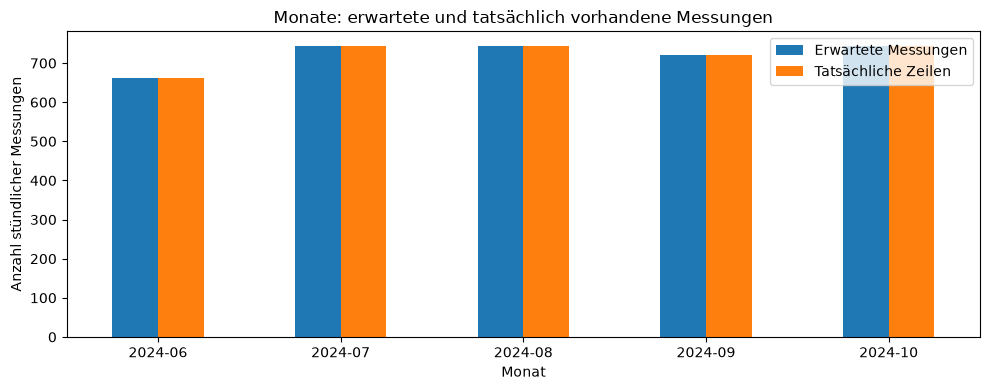

In [5]:
# Zahl der erwarteten Messungen anhand des stündlichen Zeitrasters bestimmen.
# WICHTIG: Der erste Zeitstempel ist erst am 03.06.2024 um 11:00 Uhr.
# Für Juni erwarten wir daher NICHT 30 * 24 Messungen.
zeit = pd.to_datetime(df["timestamp"])
start, ende = zeit.min(), zeit.max()
erwartete_zeiten = pd.date_range(start=start, end=ende, freq="h")
monate = erwartete_zeiten.to_period("M").astype(str)
erwartet = pd.Series(monate).value_counts().sort_index()
vorhanden = zeit.dt.to_period("M").astype(str).value_counts().sort_index()
monatsvergleich = pd.DataFrame({"Erwartete Messungen": erwartet, "Tatsächliche Zeilen": vorhanden}).fillna(0).astype(int)
monatsvergleich["Differenz"] = monatsvergleich["Erwartete Messungen"] - monatsvergleich["Tatsächliche Zeilen"]
monatsvergleich["Abdeckung (%)"] = (monatsvergleich["Tatsächliche Zeilen"] / monatsvergleich["Erwartete Messungen"] * 100).round(2)
print("Zeitspanne:", start, "bis", ende)
print("Abstände zwischen Messzeitpunkten (häufigste):")
display(zeit.diff().value_counts().head())
display(monatsvergleich)
ax = monatsvergleich[["Erwartete Messungen", "Tatsächliche Zeilen"]].plot.bar(figsize=(10, 4), rot=0, title="Monate: erwartete und tatsächlich vorhandene Messungen")
ax.set_xlabel("Monat")
ax.set_ylabel("Anzahl stündlicher Messungen")
plt.tight_layout()
plt.show()
# Anzahl vollständig vorhandener Zeilen sagt nichts über fehlende Messwerte innerhalb der Zeilen aus.

**Learning:** Wir haben gelernt, dass die vorhandenen Zeitstempel die Grundlage bilden. Erst danach lassen sich echte Zeitlücken von einem unvollständigen Startmonat unterscheiden.Daraus haben wir erkannt eine vollständige Zeitachse bedeutet nicht vollständige Messwerte: Die Zeilen existieren, aber Sensorwerte darin können trotzdem fehlen

**Interpretation der Monatsabdeckung:** Die Messreihe beginnt am **03.06.2024 um 11:00 Uhr** und enthält danach stündliche Zeitpunkte bis zum **31.10.2024 um 23:00 Uhr**. Deswegen sind im Juni nur 661 statt 720 Stunden im beobachteten Zeitraum zu erwarten. Für Juli, August, September und Oktober entspricht die Zeilenanzahl den jeweiligen Kalendertagen × 24 Stunden. Das bedeutet **nicht**, dass alle Sensorwerte in diesen Zeilen vorhanden sind: Fehlende Sensorwerte werden separat in der NaN-Analyse untersucht. Die Soll-Zahlen beziehen sich auf den erfassten Zeitraum und ein stündliches Messraster.


ANALYSE FEHLENDER WERTE


co2                  927
ufp                  777
o3                   747
pm25_lowcost         461
rain_vol             428
pressure             428
relative_humidity    428
temperature          428
wind_speed           428
glob_rad             428
wind_direction       428
pm25_target          204
no                    22
no2                   22
black_carbon           2
timestamp              0
year_month             0
dtype: int64

Gesamtanzahl fehlender Werte: 6158


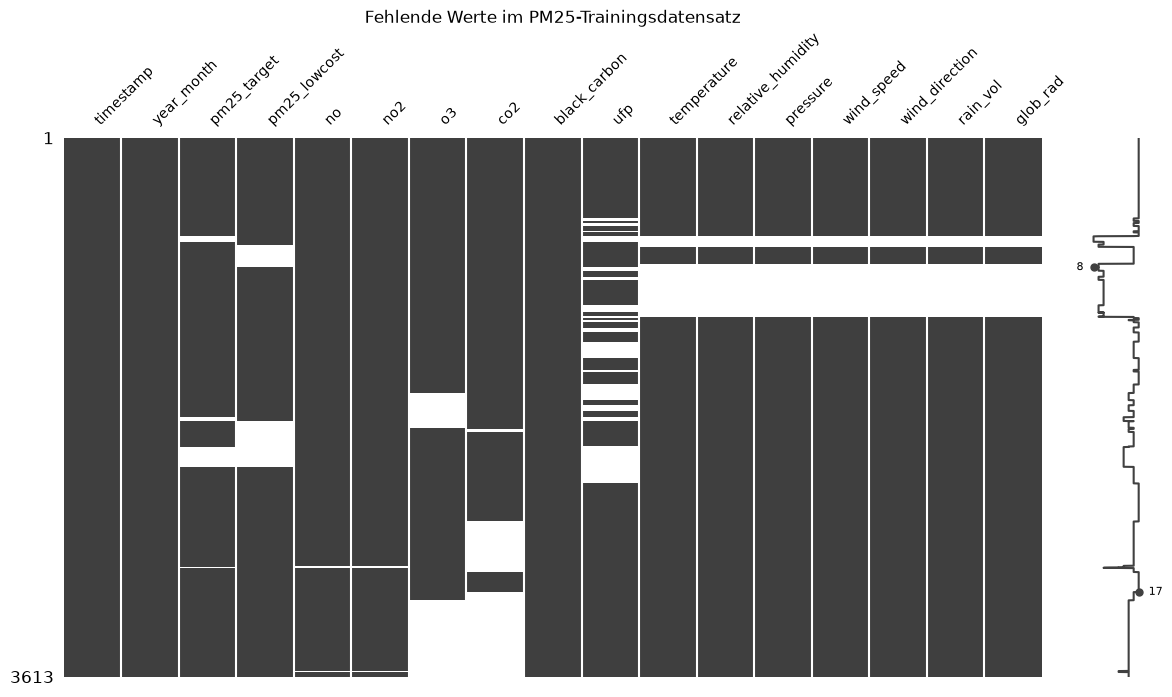

In [6]:
# Analyse der fehlenden Werte
print("\n" + "=" * 80)
print("ANALYSE FEHLENDER WERTE")
print("=" * 80)

# Fehlende Werte pro Spalte zählen und absteigend sortieren
display(df.isnull().sum().sort_values(ascending=False))

# Gesamtanzahl der fehlenden Werte berechnen
print("Gesamtanzahl fehlender Werte:", df.isnull().sum().sum())

# Visuelle Darstellung der fehlenden Werte
if msno is not None:
    msno.matrix(df, figsize=(14, 7), fontsize=10)
else:
    # Alternative ohne missingno: Weiß = fehlend, Schwarz = vorhanden
    plt.figure(figsize=(14, 7))
    plt.imshow(df.isnull(), aspect="auto", cmap="gray", interpolation="nearest")
    plt.xticks(range(len(df.columns)), df.columns, rotation=65, ha="right")
    plt.ylabel("Messungen")

plt.title("Fehlende Werte im PM25-Trainingsdatensatz")
plt.show()

### Verteilungen, Boxplots und Zusammenhänge

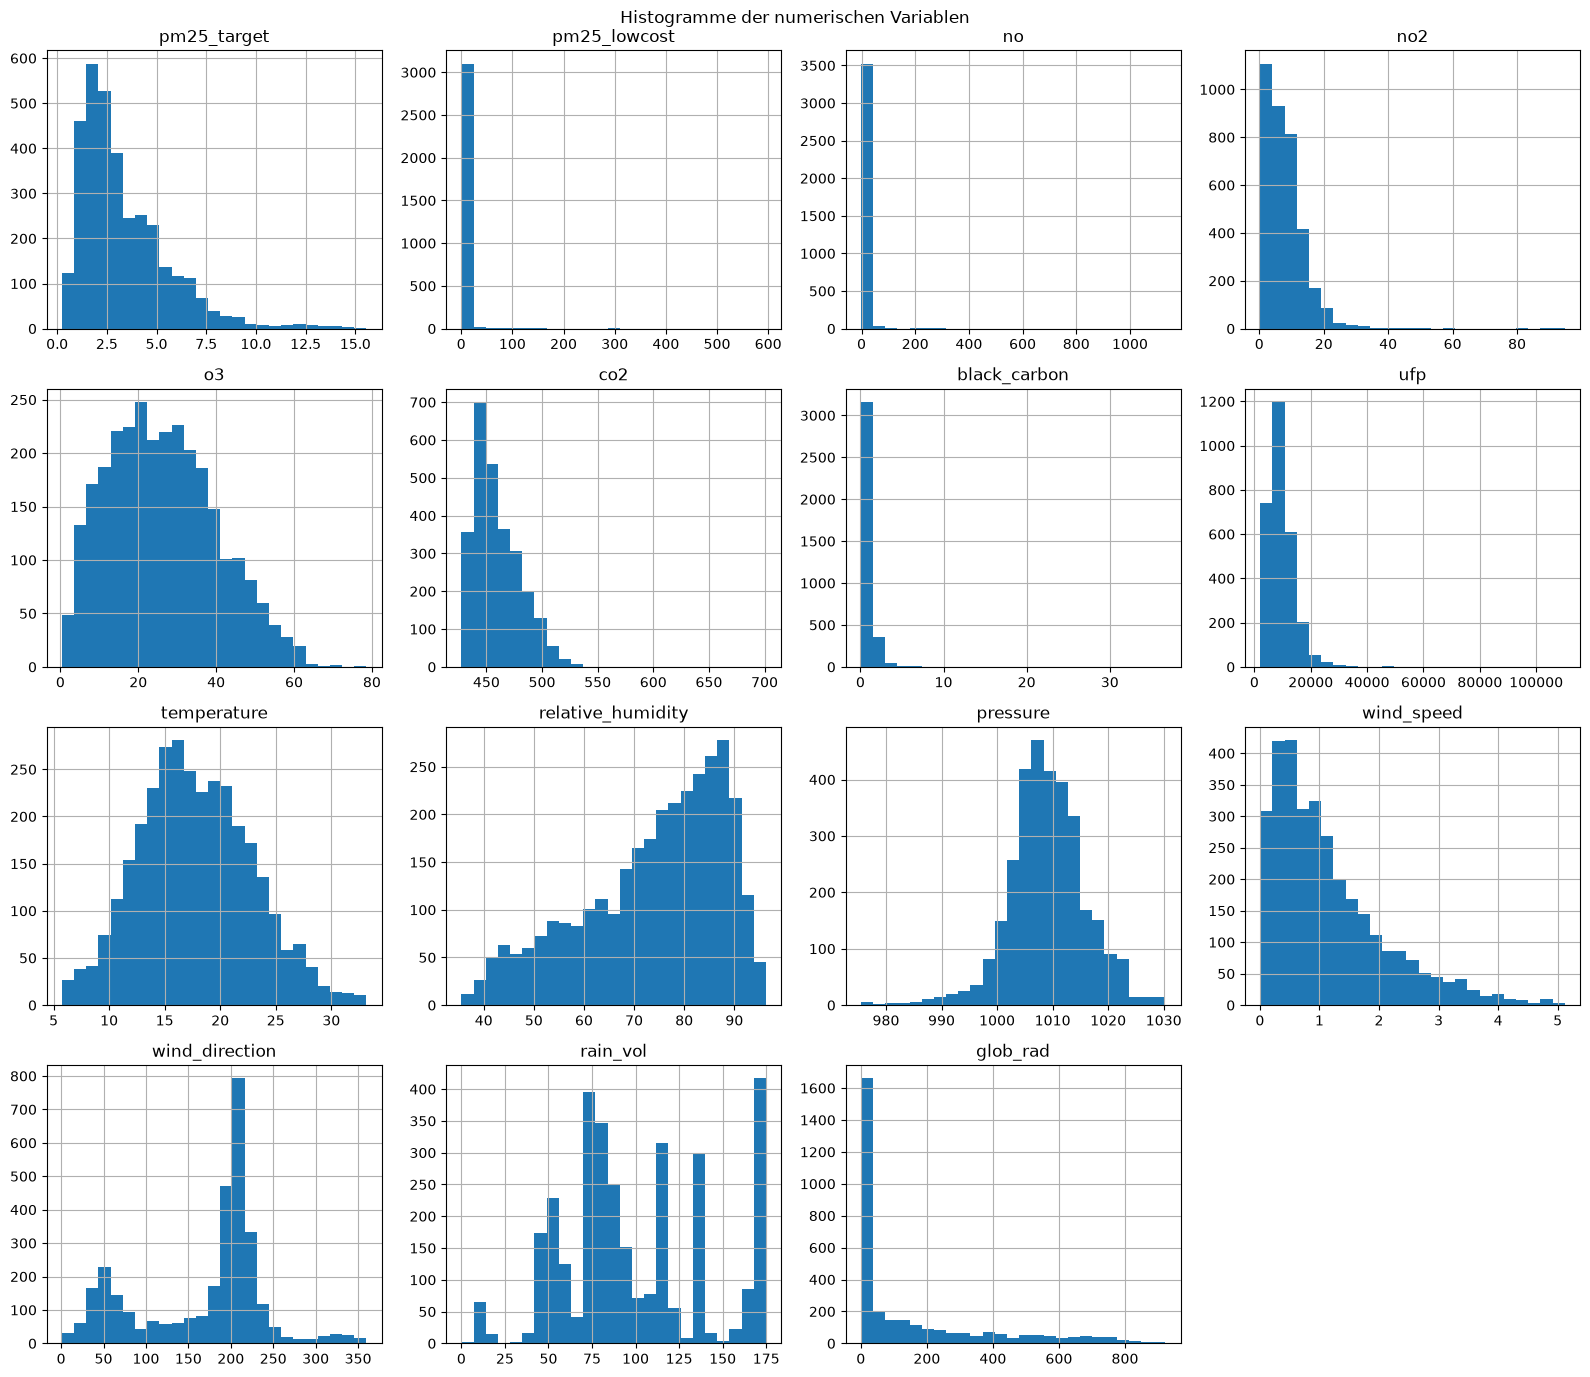

In [7]:
df.select_dtypes(include="number").hist(bins=25, figsize=(16,14))
plt.suptitle("Histogramme der numerischen Variablen")
plt.tight_layout()
plt.show()

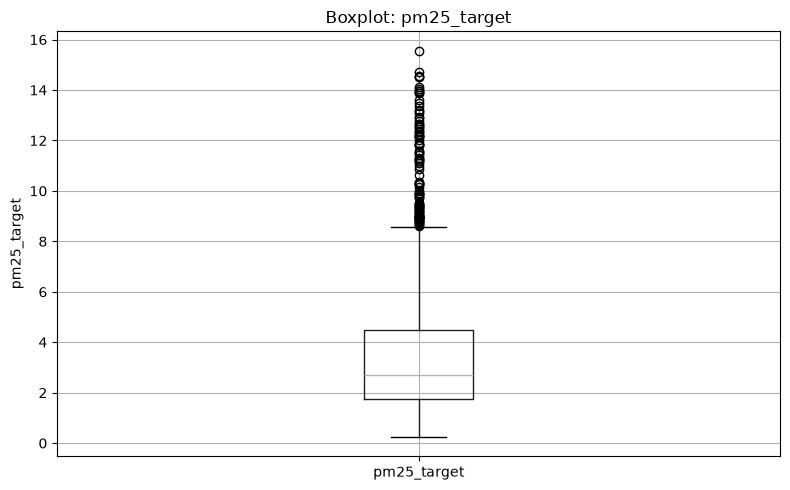

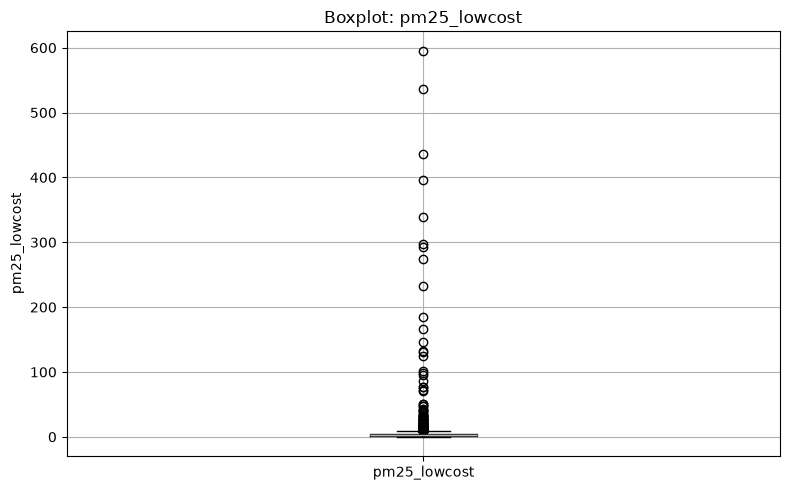

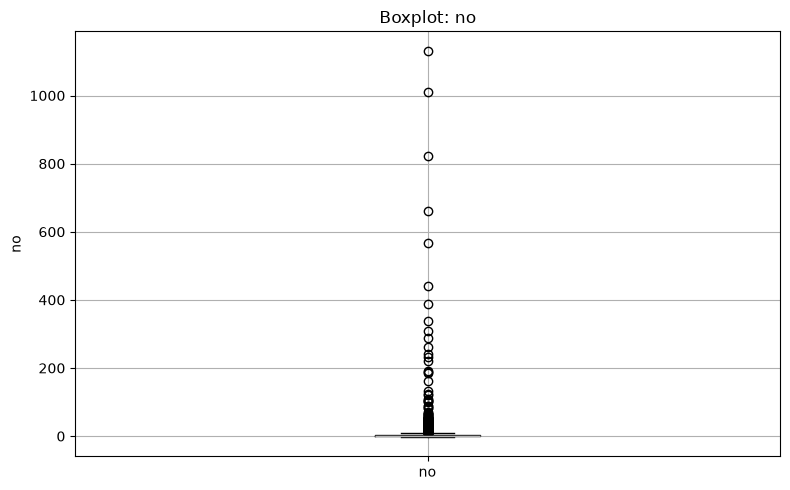

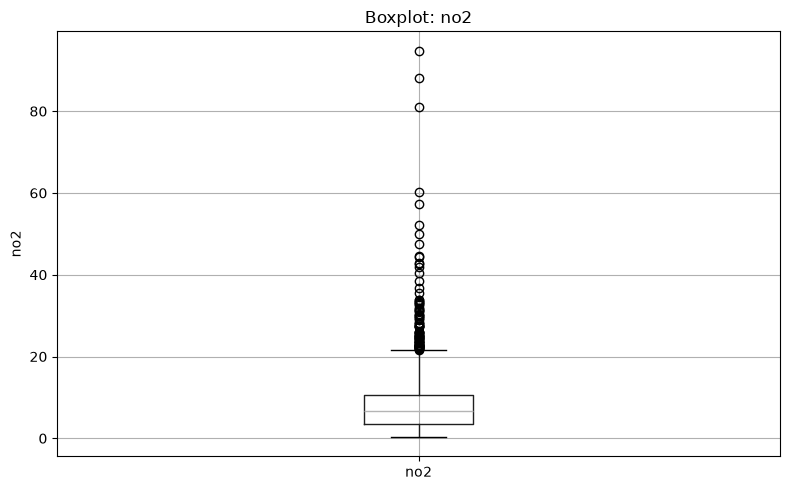

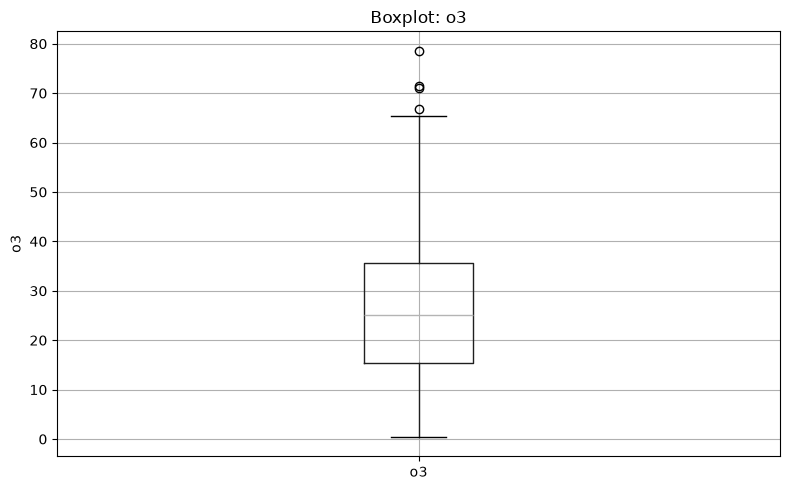

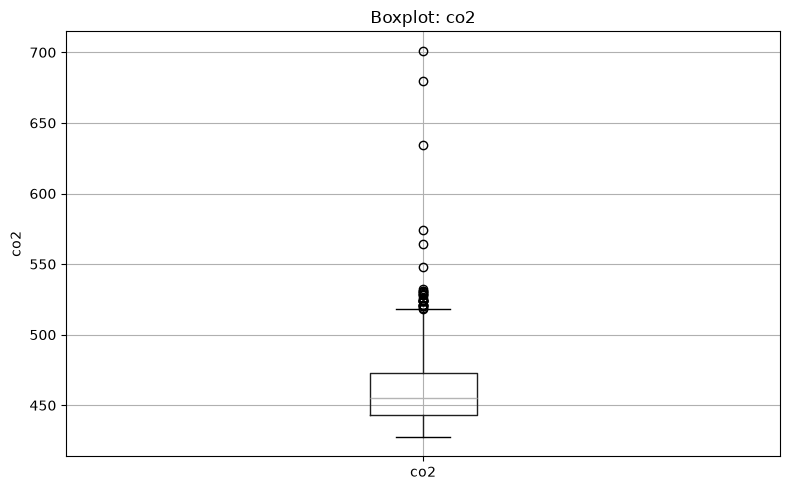

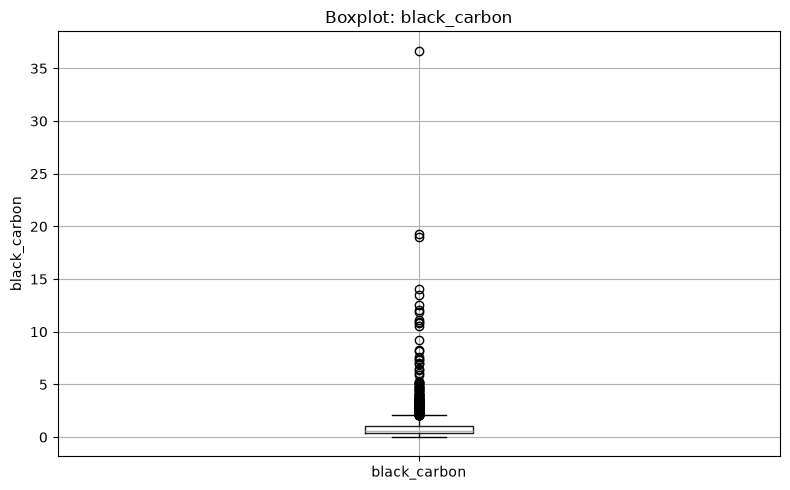

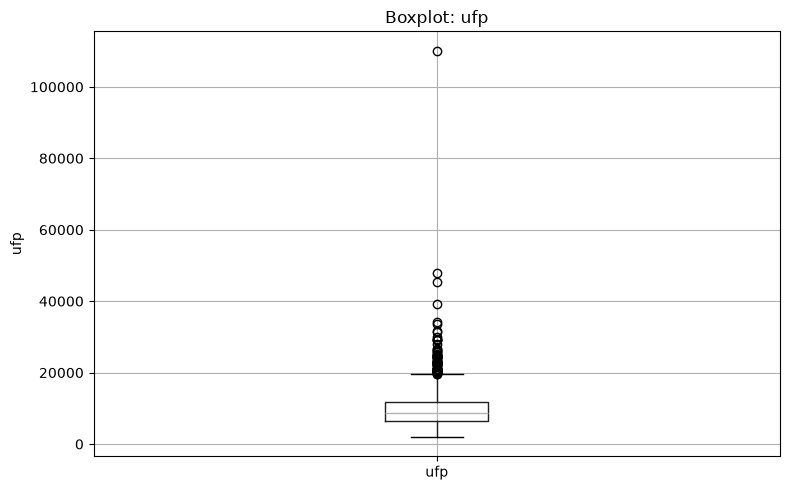

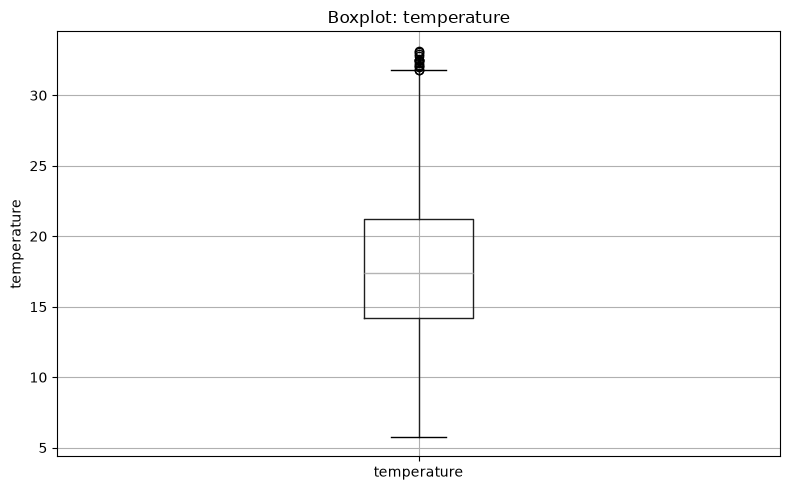

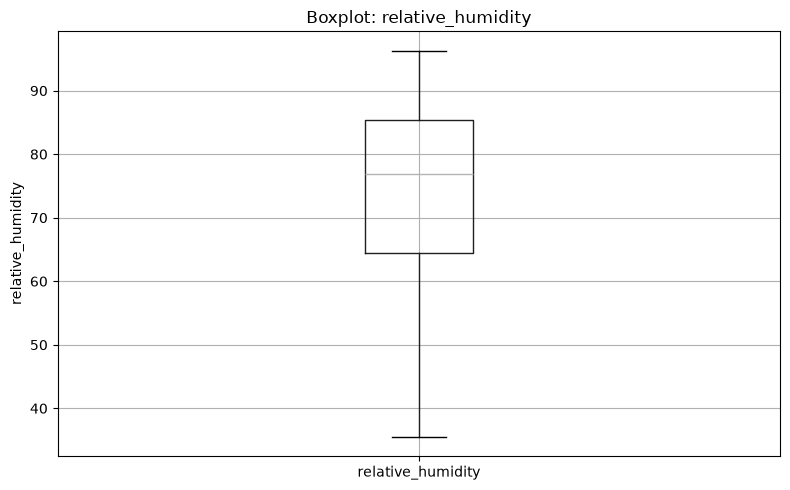

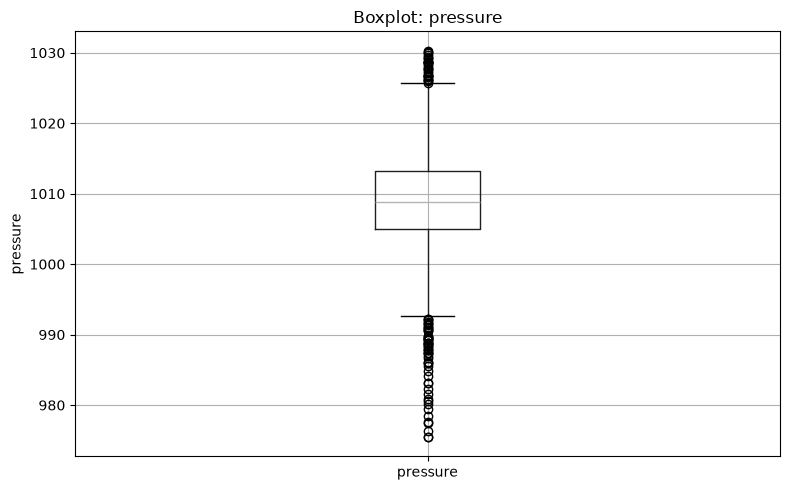

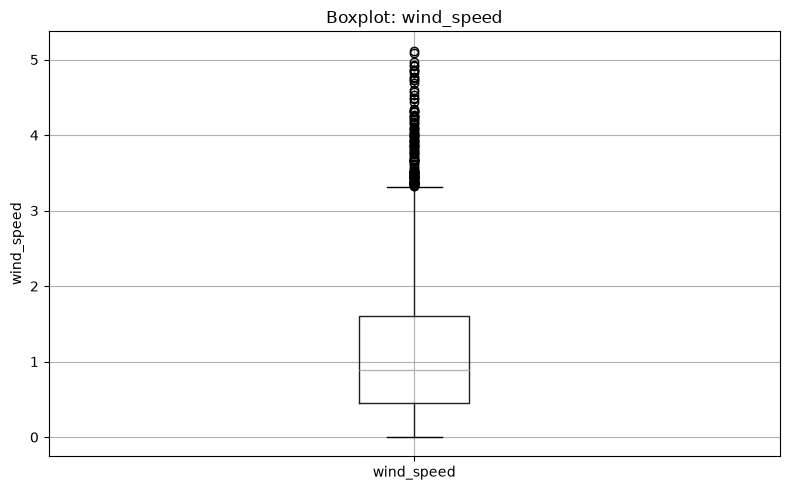

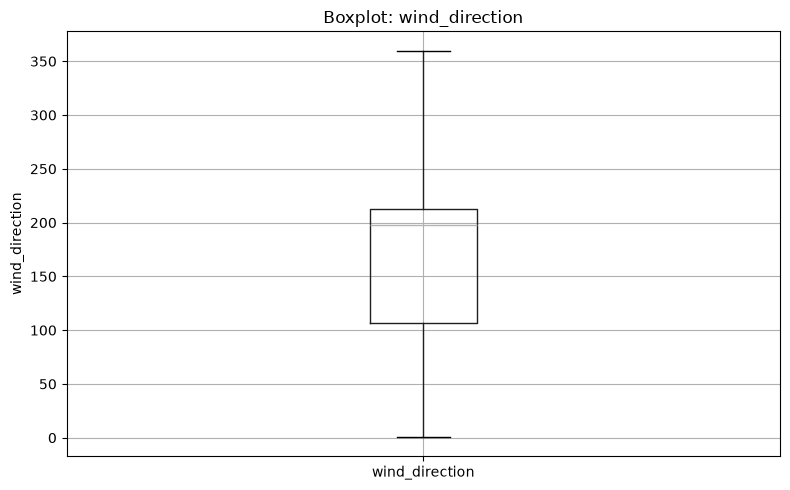

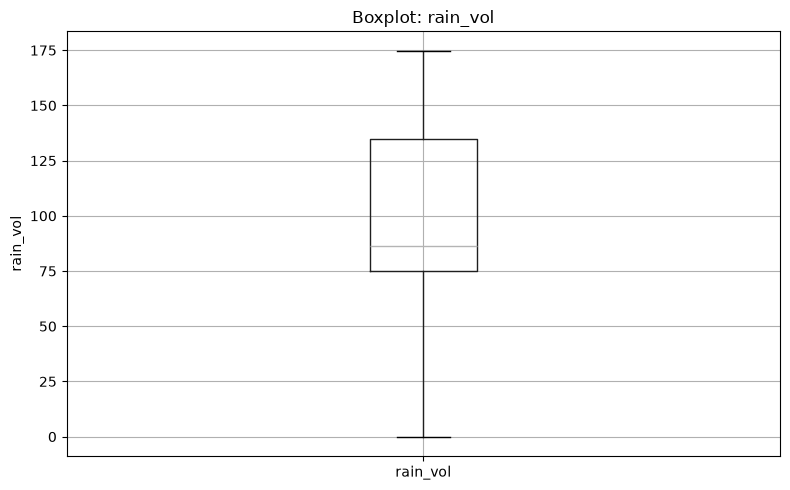

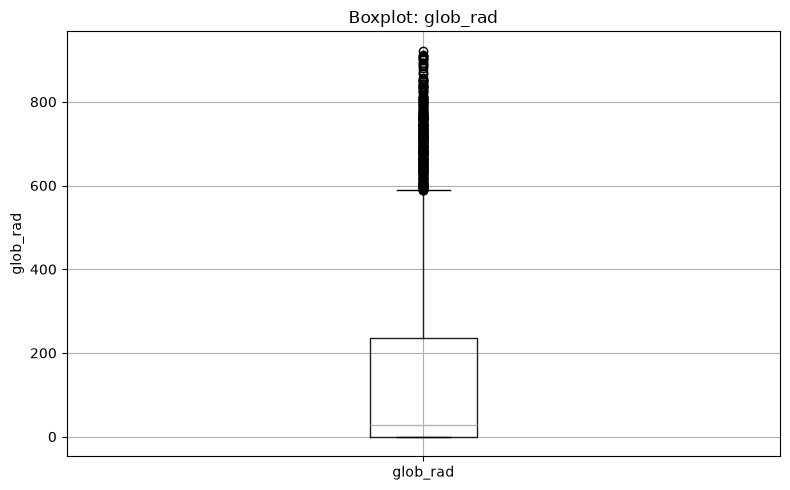

In [8]:
cols = df.select_dtypes(include="number").columns.tolist()

# Für jedes Feature ein Boxplot
for col in cols:
    df.boxplot(column=col, figsize=(8, 5), rot=0)

    plt.title("Boxplot: " + col)
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

**Lerning:** Bei der visualisierung der Heatmap hatte Luis ein Problem und konnte den Folgenden Codeblock nicht ausführen. Bei der Fehlersuche sind wir dann zu dem Erkenntnis gekommen, dass der Kernel den Luis verwendete eine ältere Version verwendete (Python 3.13.5) durch das Aktualisieren auf die Version 3.14 konnten wir letzendlich das Problem lösen.

,pm25_target,pm25_lowcost,no,no2,o3,co2,black_carbon,ufp,temperature,relative_humidity,pressure,wind_speed,wind_direction,rain_vol,glob_rad
pm25_target,1.000000,0.079080,0.062023,0.251434,0.001535,0.246649,0.304341,0.259145,0.131985,0.117563,0.241631,-0.187832,-0.168721,-0.004144,0.035941
pm25_lowcost,0.079080,1.000000,0.005144,0.045588,-0.153761,0.129620,0.028256,-0.044596,-0.207869,0.179469,0.174059,0.025729,0.034973,0.117282,-0.096712
no,0.062023,0.005144,1.000000,0.578172,-0.090074,0.410201,0.708824,0.471290,-0.083879,0.122381,0.087449,-0.093178,-0.012317,0.244804,-0.015383
no2,0.251434,0.045588,0.578172,1.000000,-0.476387,0.655728,0.668831,0.580505,-0.107864,0.343428,0.149851,-0.329415,0.061033,0.151998,-0.276250
o3,0.001535,-0.153761,-0.090074,-0.476387,1.000000,-0.685182,-0.171845,-0.161044,0.614385,-0.811682,-0.082717,0.236809,-0.265262,-0.196179,0.501727
co2,0.246649,0.129620,0.410201,0.655728,-0.685182,1.000000,0.445863,0.260585,-0.313842,0.656304,0.081908,-0.245005,0.210526,0.066661,-0.402348
black_carbon,0.304341,0.028256,0.708824,0.668831,-0.171845,0.445863,1.000000,0.628952,-0.001692,0.167695,0.107389,-0.171813,0.013128,0.203867,-0.067543
ufp,0.259145,-0.044596,0.471290,0.580505,-0.161044,0.260585,0.628952,1.000000,0.186068,-0.019234,0.131297,-0.280591,-0.065482,-0.085474,0.046785
temperature,0.131985,-0.207869,-0.083879,-0.107864,0.614385,-0.313842,-0.001692,0.186068,1.000000,-0.612303,-0.218823,0.107562,-0.149702,-0.515393,0.431617
relative_humidity,0.117563,0.179469,0.122381,0.343428,-0.811682,0.656304,0.167695,-0.019234,-0.612303,1.000000,0.046743,-0.233914,0.239731,0.320063,-0.588084


Korrelationen mit Referenz-PM2.5:


pm25_target          1.000000
black_carbon         0.304341
ufp                  0.259145
no2                  0.251434
co2                  0.246649
pressure             0.241631
temperature          0.131985
relative_humidity    0.117563
pm25_lowcost         0.079080
no                   0.062023
glob_rad             0.035941
o3                   0.001535
rain_vol            -0.004144
wind_direction      -0.168721
wind_speed          -0.187832
Name: pm25_target, dtype: float64

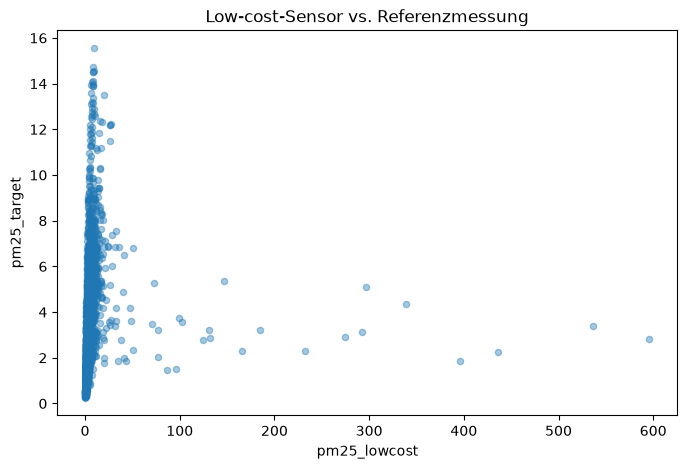

In [9]:
corr = df.select_dtypes(include="number").corr()
display(corr.style.background_gradient(cmap="coolwarm"))
print("Korrelationen mit Referenz-PM2.5:")
display(corr["pm25_target"].sort_values(ascending=False))
df.plot.scatter(x="pm25_lowcost",y="pm25_target",figsize=(8,5),alpha=0.4)
plt.title("Low-cost-Sensor vs. Referenzmessung")
plt.show()

**Learning:** Da wir in der ersten Heatmap feststellten, dass wir einige Features haben, bei dem die Korrelation zum Label pm25_target zwischen den Werten -0.1 bis +0.1 lagen, und diese die Lesbarkeit einschränkten, erstellten wir eine weitere Heatmap mit der relevanz +- 0.15

In [10]:
# Korrelationsmatrix für alle numerischen Spalten berechnen
corr = df.select_dtypes(include="number").corr()

# Absolute Korrelation aller Features mit der Zielvariable pm25_target bestimmen
# Durch abs() werden auch negative Korrelationen berücksichtigt
relevanz = corr["pm25_target"].abs()

# Nur Features auswählen, deren absolute Korrelation mindestens 0.15 beträgt
relevante_features = relevanz[relevanz >= 0.15].index.tolist()

# pm25_lowcost zusätzlich aufnehmen, da es für die Baseline benötigt wird
if "pm25_lowcost" not in relevante_features:
    relevante_features.append("pm25_lowcost")

# Zielvariable an die erste Stelle setzen
# Restliche Features nach ihrer absoluten Korrelation absteigend sortieren
relevante_features = ["pm25_target"] + [
    feature for feature in relevanz.sort_values(ascending=False).index
    if feature in relevante_features and feature != "pm25_target"
]

# Neue Korrelationsmatrix nur mit den ausgewählten Features erstellen
corr_relevant = df[relevante_features].corr()

# Heatmap als farbige Tabelle anzeigen
# Rot = positive Korrelation, Blau = negative Korrelation
display(corr_relevant.style.background_gradient(cmap="coolwarm"))

,pm25_target,black_carbon,ufp,no2,co2,pressure,wind_speed,wind_direction,pm25_lowcost
pm25_target,1.000000,0.304341,0.259145,0.251434,0.246649,0.241631,-0.187832,-0.168721,0.079080
black_carbon,0.304341,1.000000,0.628952,0.668831,0.445863,0.107389,-0.171813,0.013128,0.028256
ufp,0.259145,0.628952,1.000000,0.580505,0.260585,0.131297,-0.280591,-0.065482,-0.044596
no2,0.251434,0.668831,0.580505,1.000000,0.655728,0.149851,-0.329415,0.061033,0.045588
co2,0.246649,0.445863,0.260585,0.655728,1.000000,0.081908,-0.245005,0.210526,0.129620
pressure,0.241631,0.107389,0.131297,0.149851,0.081908,1.000000,-0.291062,-0.183658,0.174059
wind_speed,-0.187832,-0.171813,-0.280591,-0.329415,-0.245005,-0.291062,1.000000,0.141304,0.025729
wind_direction,-0.168721,0.013128,-0.065482,0.061033,0.210526,-0.183658,0.141304,1.000000,0.034973
pm25_lowcost,0.079080,0.028256,-0.044596,0.045588,0.129620,0.174059,0.025729,0.034973,1.000000


In [11]:
num = df.select_dtypes(include="number")
q1 = num.quantile(0.25)
q3 = num.quantile(0.75)
iqr = q3-q1
outliers = ((num.lt(q1-1.5*iqr)) | (num.gt(q3+1.5*iqr))).sum()
display(pd.DataFrame({"Minimum":num.min(),"Maximum":num.max(),"IQR-Ausreißer":outliers,"Anteil_%":(outliers/len(df)*100).round(2)}).sort_values("IQR-Ausreißer",ascending=False))

,Minimum,Maximum,IQR-Ausreißer,Anteil_%
no,-2.700,1131.700,433,11.98
glob_rad,0.000,922.239,259,7.17
pm25_lowcost,0.300,595.530,238,6.59
black_carbon,0.045,36.684,211,5.84
wind_speed,0.006,5.119,122,3.38
pm25_target,0.240,15.560,98,2.71
no2,0.300,94.800,87,2.41
pressure,975.468,1030.293,85,2.35
ufp,2077.700,110138.800,77,2.13
co2,427.500,701.200,28,0.77


### Interpretation für Aufgabe 2 – Datenqualität und Vorbereitung

- **Fehlende Messwerte:** Bei einigen Features fehlen Einträge. Diese werden bei der späteren Modellierung mit Trainingsmedianen aufgefüllt. Der Median ist robust gegenüber extremen Werten.
- **Fehlende Labels:** `pm25_target` muss für überwachtes Training bekannt sein. Zeilen ohne Zielwert werden nur aus dem Modelltrainings-DataFrame ausgeschlossen; `df` bleibt unverändert.
- **Ausreißer:** Boxplots zeigen auffällige Extremwerte, die in Task 2 fachlich überprüft werden sollten. Ein statistisch auffälliger Messwert ist nicht automatisch ein Messfehler.
- **Skalen:** Unterschiedliche Einheiten von Temperatur, Druck und Schadstoffen erschweren den direkten Vergleich von Koeffizienten. Eine Standardisierung kann in Task 2 untersucht werden.
- **Zeit- und Monatsinformationen:** `timestamp` ist keine direkt numerische Eingabe für die hier verwendete lineare Regression. Die Monatszählung belegt ein durchgängiges stündliches Zeitraster innerhalb des erfassten Zeitraums, nicht vollständig beobachtete Sensorwerte.

## 1b – Feature Importance durch Korrelation und schrittweise lineare Regression

**Kursbezug:** `Python Labs/10c - Feature Selection for Regression/FeatureSelection.ipynb` verwendet `numeric_features.corrwith(label)` sowie `abs().sort_values(ascending=False)` zur Auswahl relevanter Merkmale.

**Ablauf:** 
(1) Baseline nur mit pm25_lowcost; 
(2) weitere Features nach der absoluten Pearson-Korrelation mit dem Label sortieren; 
(3) pro Schritt ein Feature ergänzen;
(4) alle Varianten anhand des Validierungs-MAE und R² vergleichen; 
(5) bestes Validierungsmodell einmalig auf dem offiziellen Test prüfen.

**Wichtig:** Die Korrelationen werden ausschließlich aus dem Trainingsanteil berechnet, nicht aus Validierungs- oder Test-Labels. Das verhindert eine Informationsübertragung aus der Validierung in die Feature-Reihenfolge.

In [12]:
# Nur gelabelte ursprüngliche Trainingszeilen für überwachtes Modelltraining
labeled = df.dropna(subset=["pm25_target"]).copy()

# 80 % Modelltraining, 20 % Validierung (wie train_test_split im Unterricht)
train, valid = train_test_split(labeled, test_size=0.2, random_state=42)
print("Ursprüngliche Trainingszeilen:", len(df))
print("Ohne Referenzlabel:", len(df) - len(labeled))
print("Training:", len(train), "Validierung:", len(valid))

Ursprüngliche Trainingszeilen: 3613
Ohne Referenzlabel: 204
Training: 2727 Validierung: 682


### Schritt 1 – Reihenfolge der Features anhand der Korrelation

Die Pearson-Korrelation beschreibt den linearen Zusammenhang zwischen einem Feature und `pm25_target`. Wir sortieren nach dem Betrag der Korrelation, weil sowohl starke positive als auch starke negative Zusammenhänge interessant sind. Die Baseline `pm25_lowcost` wird unabhängig von ihrer Korrelationsstärke zuerst verwendet, weil sie in Aufgabe 1b vorgeschrieben ist.

Eine hohe Einzelkorrelation garantiert keine Verbesserung in Kombination mit anderen Features. Deshalb messen wir bei jedem weiteren Schritt die Validierungsqualität.

In [13]:
# Unterrichtsmethode: corrwith(label) und absolute Korrelation absteigend sortieren
numeric_features = train.select_dtypes(include="number").drop(columns=["pm25_target", "pm25_lowcost"])
label = train["pm25_target"]
numeric_features_corr = numeric_features.corrwith(label)
sorted_features = numeric_features_corr.abs().sort_values(ascending=False).index.tolist()
features = ["pm25_lowcost"] + sorted_features

print("Reihenfolge für die schrittweise Ergänzung:")
display(pd.DataFrame({"Feature": sorted_features, "Korrelation mit pm25_target": numeric_features_corr.loc[sorted_features].values}).round(4))
print("Baseline-Feature: pm25_lowcost")

Reihenfolge für die schrittweise Ergänzung:


,Feature,Korrelation mit pm25_target
0,black_carbon,0.2686
1,ufp,0.2502
2,pressure,0.2421
3,co2,0.2367
4,no2,0.2342
5,wind_speed,-0.1800
6,wind_direction,-0.1698
7,relative_humidity,0.1170
8,temperature,0.1154
9,glob_rad,0.0399


Baseline-Feature: pm25_lowcost


### Schritt 2 – Fehlende Features behandeln und ein Modell bewerten

`prepare()` ersetzt fehlende Eingaben mit dem Median aus dem jeweiligen Trainingsanteil. `evaluate()` trainiert für eine Feature-Liste immer eine neue `LinearRegression` und gibt Modell, MAE und R² auf der Validierung zurück.

- MAE = Differenz zwischen dem vorhergesagten und dem prognostizierten Wert.
- R² = Beschreibt, wie gut das Modell die Varianz erklärt.

Fehlende Zielwerte der offiziellen Testdaten werden niemals verändert.

In [14]:
def prepare(train_part, eval_part, selected):
    # Nur Trainingsdaten liefern die Mediane, auch für die Validierung
    medians = train_part[selected].median()
    X_train = train_part[selected].fillna(medians)
    X_eval = eval_part[selected].fillna(medians)
    return X_train, X_eval


def evaluate(selected, train_part=train, eval_part=valid):
    # Ein Modell trainieren und auf unbekannter Validierung bewerten
    X_train, X_eval = prepare(train_part, eval_part, selected)
    model = linear_model.LinearRegression()
    model.fit(X_train, train_part["pm25_target"])
    prediction = model.predict(X_eval)
    mae = mean_absolute_error(eval_part["pm25_target"], prediction)
    r2 = model.score(X_eval, eval_part["pm25_target"])
    return model, mae, r2

**Learning:** `prepare()` und `evaluate()` trennen das Aufbereiten der Features von Modelltraining und Bewertung. Für jede Variante gilt derselbe Ablauf. Wir haben dabei besonders darauf geachtet, dass Imputationswerte aus Training und nicht aus Validierung oder offiziellem Test stammen.

### Schritt 3 – Baseline erstellen und Features Schritt für Schritt ergänzen

Die Features werden nicht anhand neuer MAE-Tests ausgewählt. Die Reihenfolge steht durch die Korrelationsmethode bereits fest. Nach jedem Ergänzungsschritt messen wir, wie sich MAE und R² ändern.

In [15]:
results = []
selected = ["pm25_lowcost"]

# Schritt 0: Baseline ausschließlich mit pm25_lowcost
model, mae, r2 = evaluate(selected)
results.append({"Schritt": 0, "Neues Feature": "Baseline", "Features": selected.copy(), "MAE": mae, "R2": r2})

# Die bereits nach Korrelation sortierten Merkmale nacheinander ergänzen
for step, new_feature in enumerate(sorted_features, start=1):
    selected.append(new_feature)
    model, mae, r2 = evaluate(selected)
    results.append({"Schritt": step, "Neues Feature": new_feature, "Features": selected.copy(), "MAE": mae, "R2": r2})

results_df = pd.DataFrame(results)
base_mae = results_df.loc[0, "MAE"]
base_r2 = results_df.loc[0, "R2"]
results_df["MAE Verbesserung absolut"] = base_mae - results_df["MAE"]
results_df["MAE Verbesserung %"] = (base_mae - results_df["MAE"]) / base_mae * 100
results_df["R2 Verbesserung absolut"] = results_df["R2"] - base_r2
results_df["MAE-Änderung ggü. Vorstufe"] = results_df["MAE"].diff()
print("Ergebnisse der schrittweisen, korrelationsbasierten Erweiterung:")
display(results_df.drop(columns="Features").round(4))

Ergebnisse der schrittweisen, korrelationsbasierten Erweiterung:


,Schritt,Neues Feature,MAE,R2,MAE Verbesserung absolut,MAE Verbesserung %,R2 Verbesserung absolut,MAE-Änderung ggü. Vorstufe
0,0,Baseline,1.7480,0.0058,0.0000,0.0000,0.0000,NaN
1,1,black_carbon,1.6038,0.1561,0.1442,8.2485,0.1503,-0.1442
2,2,ufp,1.6047,0.1563,0.1433,8.1981,0.1505,0.0009
3,3,pressure,1.5694,0.1884,0.1785,10.2129,0.1826,-0.0352
4,4,co2,1.5498,0.1915,0.1982,11.3380,0.1857,-0.0197
5,5,no2,1.5498,0.1915,0.1982,11.3391,0.1857,-0.0000
6,6,wind_speed,1.5415,0.1963,0.2065,11.8133,0.1905,-0.0083
7,7,wind_direction,1.5233,0.2261,0.2247,12.8530,0.2203,-0.0182
8,8,relative_humidity,1.5219,0.2250,0.2261,12.9349,0.2192,-0.0014
9,9,temperature,1.3981,0.3118,0.3499,20.0173,0.3061,-0.1238


### Schritt 4 – MAE und R² übersichtlich vergleichen

Die vier Diagramme stehen **untereinander**: Validierungs-MAE, Validierungs-R², absolute und relative MAE-Verbesserung. So bleiben die Skalen unabhängig und die Entwicklung pro hinzugefügtem Feature gut lesbar. Die Diagramme zeigen unterschiedliche Aspekte derselben Auswertung und dürfen nicht allein anhand der Balken- oder Linienhöhe miteinander gleichgesetzt werden.

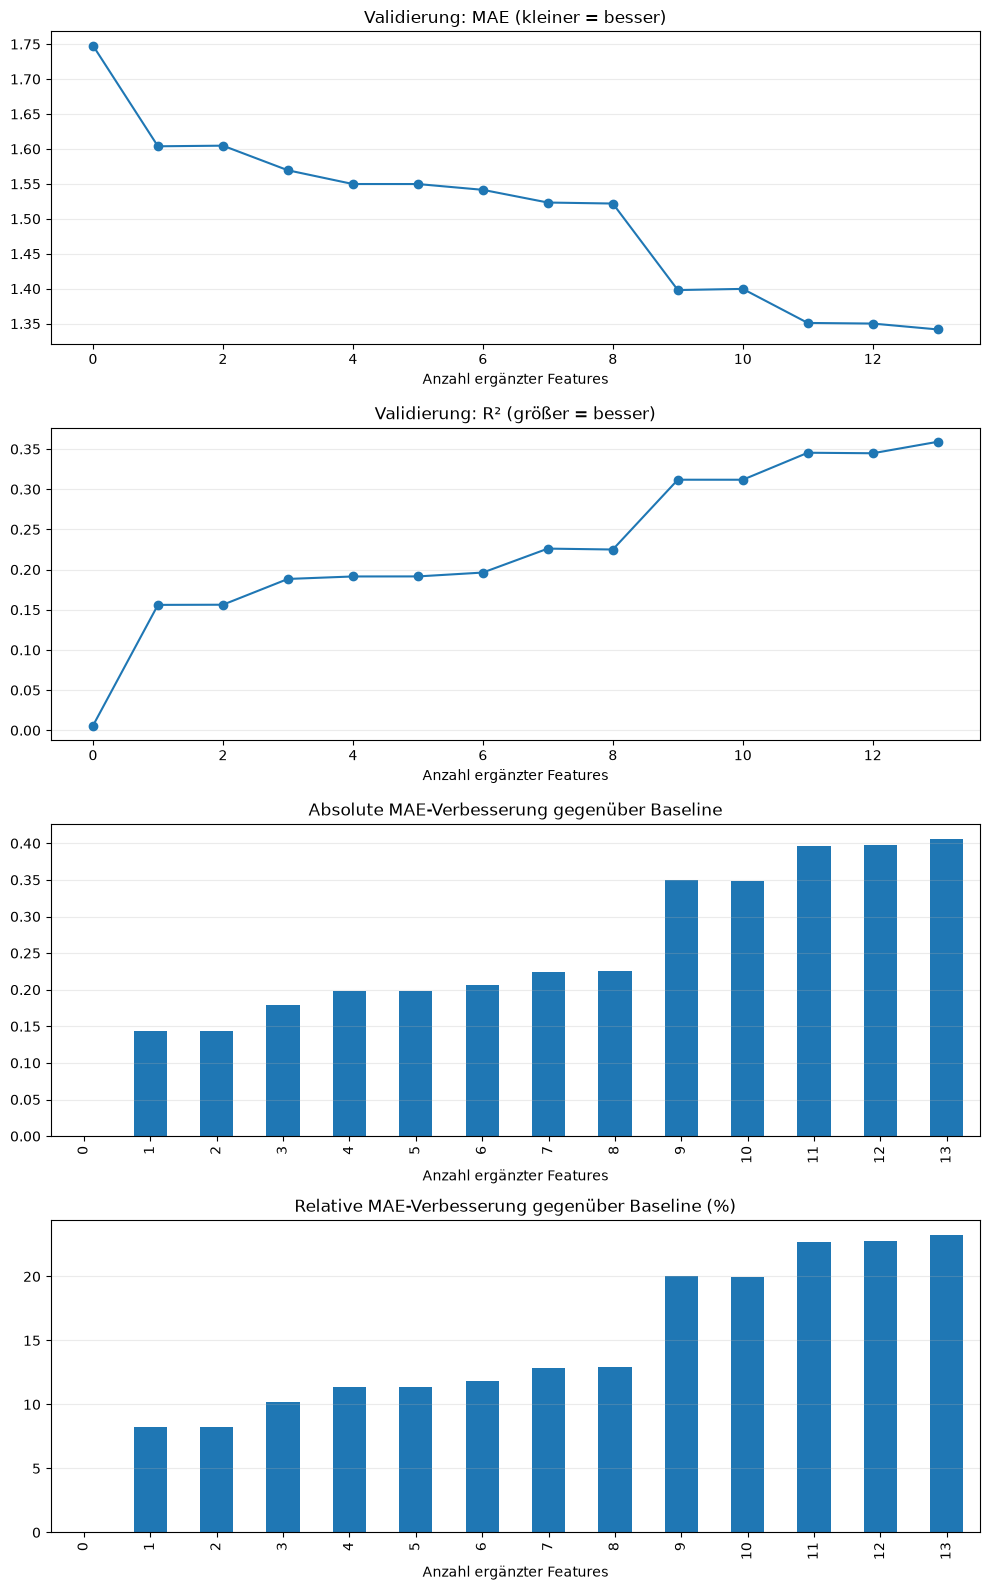

In [16]:
fig, axes = plt.subplots(4, 1, figsize=(10, 16))

results_df.plot(
    x="Schritt",
    y="MAE",
    marker="o",
    ax=axes[0],
    legend=False,
    title="Validierung: MAE (kleiner = besser)"
)

results_df.plot(
    x="Schritt",
    y="R2",
    marker="o",
    ax=axes[1],
    legend=False,
    title="Validierung: R² (größer = besser)"
)

results_df.plot(
    x="Schritt",
    y="MAE Verbesserung absolut",
    kind="bar",
    ax=axes[2],
    legend=False,
    title="Absolute MAE-Verbesserung gegenüber Baseline"
)

results_df.plot(
    x="Schritt",
    y="MAE Verbesserung %",
    kind="bar",
    ax=axes[3],
    legend=False,
    title="Relative MAE-Verbesserung gegenüber Baseline (%)"
)

for ax in axes:
    ax.set_xlabel("Anzahl ergänzter Features")
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

**Learning:** Beim Erstellen der Diagramme wurde deutlich, dass eine mathematisch korrekte Grafik noch nicht automatisch verständlich ist. Wir haben vier Kennzahlen zunächst in einer kompakten Anordnung betrachtet und uns anschließend für vier Diagramme untereinander entschieden. Dadurch lassen sich Achsen, Einheiten und Titel eindeutig zuordnen und der Vergleich untereinander ist ersichtlicher. -> **Für zukünftige Projekte:** Bereits vor dem Plotten festlegen, welche Frage jedes Diagramm beantworten soll, und die Achsen entsprechend beschriften.

### Schritt 5 – Bestes Validierungsmodell bestimmen

**Erst nach dem Vergleich** wählen wir die Feature-Kombination mit dem kleinsten Validierungs-MAE. Alle bisherigen Schritte verwenden ausschließlich Training und Validierung. Die offiziellen Testdaten sind dabei unberührt.

In [17]:
best = results_df.loc[results_df["MAE"].idxmin()]
best_features = best["Features"]
print("Beste Anzahl Features:", len(best_features))
print("Ausgewählte Feature-Kombination:", best_features)
print("Validierung MAE:", round(best["MAE"], 4), "R²:", round(best["R2"], 4))
print("Validierungs-Baseline MAE:", round(base_mae, 4), "R²:", round(base_r2, 4))

Beste Anzahl Features: 14
Ausgewählte Feature-Kombination: ['pm25_lowcost', 'black_carbon', 'ufp', 'pressure', 'co2', 'no2', 'wind_speed', 'wind_direction', 'relative_humidity', 'temperature', 'glob_rad', 'no', 'rain_vol', 'o3']
Validierung MAE: 1.3417 R²: 0.359
Validierungs-Baseline MAE: 1.748 R²: 0.0058


### Schritt 6 – Endmodell und Baseline auf dem offiziellen Testdatensatz

Wir trainieren die ausgewählte Kombination erneut mit allen ursprünglich gelabelten Trainingszeilen. Eine neue Baseline wird mit denselben Trainingszeilen gefittet. Beide Modelle erhalten auf den offiziellen Testdaten Vorhersagen. Die 1.464 Testzeilen werden nicht gelöscht und die Zielwerte werden nicht verändert. MAE/R² werden nur anhand vorhandener `pm25_target`-Werte berechnet.

In [18]:
# Vorberaitung Import Endmodell
from sklearn.metrics import r2_score

final_train = labeled.copy()
test = pd.read_csv("pm25_test.csv")
assert len(test) == 1464
assert "pm25_target" in test.columns

In [19]:
# Imputation: ausschließlich Mediane der endgültigen Trainingsdaten
train_medians = final_train[best_features].median()
X_final = final_train[best_features].fillna(train_medians)
X_test = test[best_features].fillna(train_medians)
final_reg = linear_model.LinearRegression()
final_reg.fit(X_final, final_train["pm25_target"])
test_predictions = final_reg.predict(X_test)

# Faire Baseline: gleiches Training und gleicher offizieller Test
base_features = ["pm25_lowcost"]
base_medians = final_train[base_features].median()
base_reg = linear_model.LinearRegression()
base_reg.fit(final_train[base_features].fillna(base_medians), final_train["pm25_target"])
baseline_predictions = base_reg.predict(test[base_features].fillna(base_medians))

# Nur MAE/R² beschränken sich auf Testzeilen mit bekanntem Zielwert
valid_target = test["pm25_target"].notna()
observed_target = test.loc[valid_target, "pm25_target"]
test_mae = mean_absolute_error(observed_target, test_predictions[valid_target.to_numpy()])
test_r2 = r2_score(observed_target, test_predictions[valid_target.to_numpy()])
base_mae_test = mean_absolute_error(observed_target, baseline_predictions[valid_target.to_numpy()])
base_r2_test = r2_score(observed_target, baseline_predictions[valid_target.to_numpy()])

print("Testzeilen insgesamt:", len(test))
print("Davon auswertbar:", int(valid_target.sum()), "ohne Label:", int((~valid_target).sum()))
print("Test – Baseline MAE / R²:", round(base_mae_test, 4), round(base_r2_test, 4))
print("Test – Feature-Modell MAE / R²:", round(test_mae, 4), round(test_r2, 4))
print("MAE-Veränderung ggü. Baseline (%):", round((base_mae_test-test_mae)/base_mae_test*100, 2))

# Original-Testdatei unverändert lassen, Vorhersagen als neue CSV exportieren
predictions_output = test.copy()
predictions_output["pm25_prediction"] = test_predictions
predictions_output.to_csv("pm25_test_predictions.csv", index=False)

Testzeilen insgesamt: 1464
Davon auswertbar: 1419 ohne Label: 45
Test – Baseline MAE / R²: 2.1627 -0.0046
Test – Feature-Modell MAE / R²: 2.2137 -0.1391
MAE-Veränderung ggü. Baseline (%): -2.36


**Learning:** Im Verlauf unserer Bearbeitung haben wir erkannt, dass die Wahl des Feature-Selection-Verfahrens einen Einfluss auf die Modellbewertung hat. Zunächst haben wir mit Greedy Forward Selection gearbeitet, bei der nach jedem Schritt das zusätzliche Feature mit dem niedrigsten Validierungs-MAE ausgewählt wird.

Bei der Überprüfung unserer Unterrichtsmaterialien haben wir festgestellt, dass wir dort die korrelationsbasierte Feature Selection mit corrwith(), abs() und sort_values() behandelt haben. Daraufhin haben wir unsere Implementierung angepasst.

Dabei haben wir gelernt, dass es wichtig ist, die Auswahlmethode nachvollziehbar zu begründen, anstatt lediglich möglichst viele Modellvarianten auszuprobieren.

Der Vergleich der bisherigen Ergebnisse zeigt, dass die Greedy-Methode zwar einen geringfügig niedrigeren Validierungsfehler erreichte, die korrelationsbasierte Methode auf den offiziellen Testdaten jedoch weniger stark von der Baseline abwich.

Unsere wichtigste Erkenntnis: Ein aufwendigeres Auswahlverfahren führt nicht zwangsläufig zu besseren Vorhersagen auf unbekannten Daten.

Bei einer erneuten Bearbeitung würden wir die im Unterricht behandelten Methoden bereits zu Beginn genauer prüfen, die Feature-Auswahl systematisch dokumentieren und stärker darauf achten, dass sämtliche Modellentscheidungen vor der abschließenden Testbewertung getroffen werden.

### Schritt 7 – Ergebnisse von Training und Test vergleichen

**Vergleich A:** Training gegen Test für dasselbe Endmodell – hilft, die Generalisierung zu untersuchen. **Vergleich B:** Baseline gegen ausgewähltes Modell – zeigt, ob zusätzliche Features auf dem Test helfen. Die Kennzahlen MAE und R² werden in **getrennten Diagrammen** dargestellt.

,Datensatz,MAE,R2
0,Training,1.3197,0.3300
1,Test,2.2137,-0.1391


,Modell,MAE,R2
0,Baseline,2.1627,-0.0046
1,Ausgewählte Features,2.2137,-0.1391


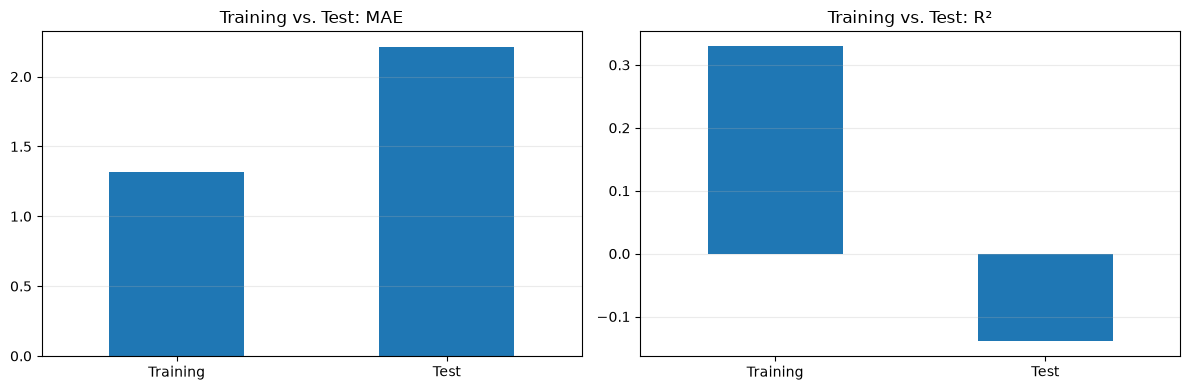

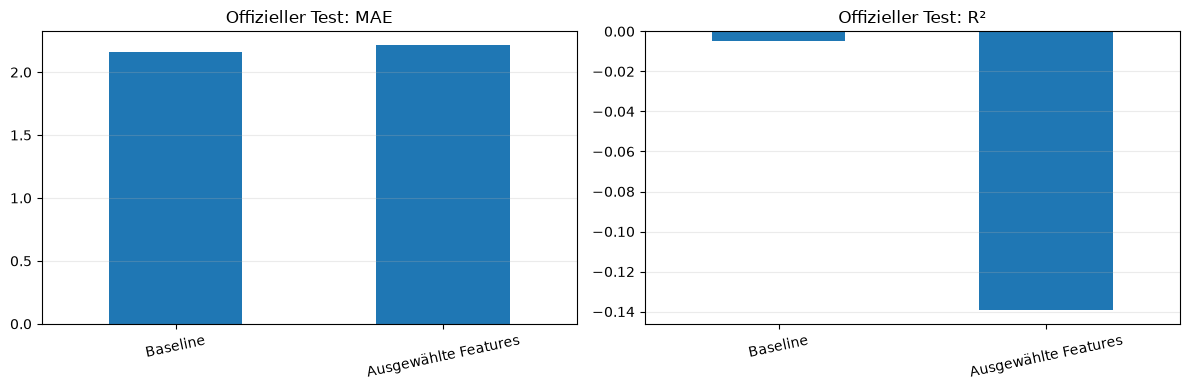

In [20]:
train_predictions = final_reg.predict(X_final)
train_mae = mean_absolute_error(final_train["pm25_target"], train_predictions)
train_r2 = r2_score(final_train["pm25_target"], train_predictions)
vergleich = pd.DataFrame({"Datensatz": ["Training", "Test"], "MAE": [train_mae, test_mae], "R2": [train_r2, test_r2]})
display(vergleich.round(4))

test_vergleich = pd.DataFrame({"Modell": ["Baseline", "Ausgewählte Features"],
                              "MAE": [base_mae_test, test_mae], "R2": [base_r2_test, test_r2]})
display(test_vergleich.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
vergleich.plot(x="Datensatz", y="MAE", kind="bar", ax=axes[0], legend=False, title="Training vs. Test: MAE")
vergleich.plot(x="Datensatz", y="R2", kind="bar", ax=axes[1], legend=False, title="Training vs. Test: R²")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
test_vergleich.plot(x="Modell", y="MAE", kind="bar", ax=axes[0], legend=False, title="Offizieller Test: MAE")
test_vergleich.plot(x="Modell", y="R2", kind="bar", ax=axes[1], legend=False, title="Offizieller Test: R²")
for ax in axes:
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=12)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

### Schritt 8 – Einfluss der ausgewählten Features darstellen

Die Regressionskoeffizienten werden mit der jeweiligen Standardabweichung multipliziert, um die Größenordnungen vergleichbarer zu machen. Das ist eine **modellabhängige Beschreibung**, keine kausale Wirkung und keine allgemeingültige Rangliste der Features.

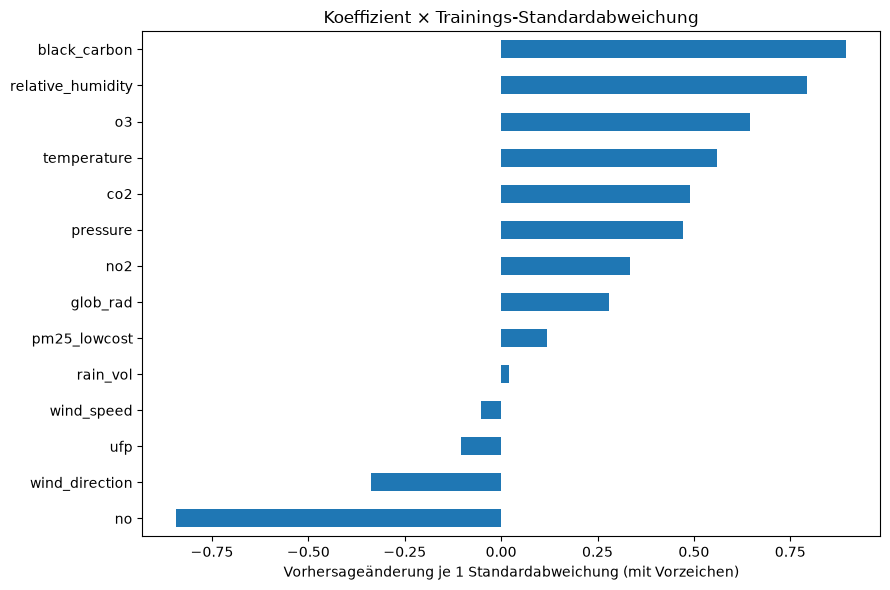

In [21]:
importance = pd.Series(final_reg.coef_ * X_final.std().values, index=best_features).sort_values()
importance.plot.barh(figsize=(9, 6), title="Koeffizient × Trainings-Standardabweichung")
plt.xlabel("Vorhersageänderung je 1 Standardabweichung (mit Vorzeichen)")
plt.tight_layout()
plt.show()

### Schritt 9 – Streudiagramme: Ist-Wert gegen Vorhersage

Vier Diagramme vergleichen Validierung und offiziellen Test sowie Baseline und ausgewählte Features. Jeder Punkt ist eine auswertbare Messung. Die gestrichelte Linie `y=x` bezeichnet perfekte Vorhersagen. Validierungsmodelle sind ausschließlich auf `train` gefittet, während die Testmodelle nach der Auswahl mit `final_train` neu trainiert wurden.

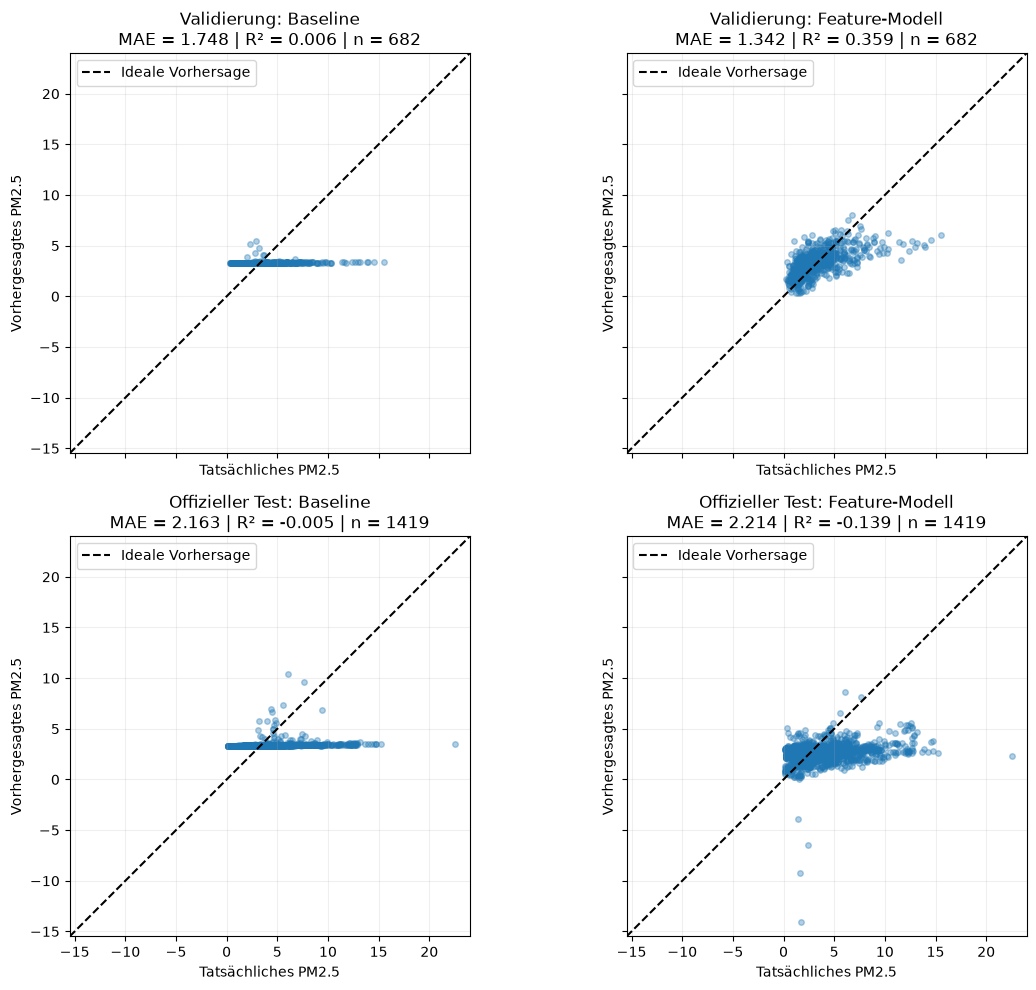

In [22]:
# Modelle für Validierungsplots separat nur mit train fitten
val_base_model, _, _ = evaluate(["pm25_lowcost"], train, valid)
val_best_model, _, _ = evaluate(best_features, train, valid)
_, X_val_base = prepare(train, valid, ["pm25_lowcost"])
_, X_val_best = prepare(train, valid, best_features)
val_base_pred = val_base_model.predict(X_val_base)
val_best_pred = val_best_model.predict(X_val_best)

mask = valid_target.to_numpy()
y_val = valid["pm25_target"].to_numpy()
y_test = test.loc[valid_target, "pm25_target"].to_numpy()
plots = [
    ("Validierung: Baseline", y_val, val_base_pred),
    ("Validierung: Feature-Modell", y_val, val_best_pred),
    ("Offizieller Test: Baseline", y_test, baseline_predictions[mask]),
    ("Offizieller Test: Feature-Modell", y_test, test_predictions[mask]),
]
all_values = np.concatenate([np.asarray(y) for _, true, pred in plots for y in (true, pred)])
small, large = float(np.min(all_values)), float(np.max(all_values))
pad = max((large-small)*0.04, 0.1)
limits = (small-pad, large+pad)
fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
for ax, (title, truth, prediction) in zip(axes.flat, plots):
    ax.scatter(truth, prediction, alpha=0.35, s=16)
    ax.plot(limits, limits, "--", color="black", lw=1.5, label="Ideale Vorhersage")
    ax.set_xlim(limits); ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    mae_plot = mean_absolute_error(truth, prediction)
    r2_plot = r2_score(truth, prediction)
    ax.set_title(f"{title}\nMAE = {mae_plot:.3f} | R² = {r2_plot:.3f} | n = {len(truth)}")
    ax.set_xlabel("Tatsächliches PM2.5")
    ax.set_ylabel("Vorhergesagtes PM2.5")
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

**Learning:** Streudiagramme ergänzen MAE und R², weil sie sichtbar machen können, bei welchen Wertebereichen sich Vorhersagen systematisch entfernen. Ein deutlich schlechterer Test als Validierung ist ein Signal, das bereits bestehende Modell zu überarbeiten oder ein neues Modell mit einer anderen Methode zum Featureselect zu erstellen . Wir sollten mögliche Unterschiede in Zeiträumen, Messbedingungen und Modellannahmen weiter untersuchen, statt einfach mehr Features hinzuzufügen.

### Interpretation und Schlussfolgerungen für Aufgabe 1b

Die Feature-Reihenfolge wurde mit `corrwith()` / `abs()` / `sort_values()` bestimmt. Die Auswahl der am besten bewerteten kumulativen Kombination erfolgte anhand des **Validierungs-MAE**. Der offizielle Test wurde erst danach durchgeführt.

**Worauf wir achten:** Niedriger MAE ist besser, höheres R² ist besser. Die Verbesserung gegenüber der Baseline auf Validierung kann auf dem offiziellen Test verschwinden. Eine negative R²-Auswertung bedeutet eine schlechtere Vorhersage als eine konstante Mittelwertprognose auf dem ausgewerteten Datensatz. Zusätzliche Features sind nicht automatisch hilfreich. Ein Unterschied zwischen Training und Test kann auf eingeschränkte Generalisierung hindeuten, beweist aber für sich allein noch kein Overfitting.

**Methodische Grenze:** Die Korrelationsrangfolge berücksichtigt bei der Sortierung nur den jeweiligen linearen Einzelzusammenhang. Sie berücksichtigt keine gemeinsamen Effekte oder Redundanzen. Die wiederholte Auswahl anhand einer Validierungsmenge kann zu optimistischen Validierungsresultaten führen.

### **Handlungsempfehlungen** 

Auf Grundlage unserer Datenexploration und der anschließenden Untersuchung der Feature Importance haben wir mehrere Datenqualitätsprobleme identifiziert, die bei der weiteren Datenaufbereitung in Aufgabe 2 berücksichtigt werden sollten.

**Umgang mit fehlenden Werten**

Ein wesentliches Problem unseres Datensatzes sind die fehlenden Messwerte. Besonders betroffen sind die Features co2 mit 927, ufp mit 777 und o3 mit 747 fehlenden Werten. Auch bei den meteorologischen Messgrößen fehlen teilweise größere zusammenhängende Datenbereiche. Wir empfehlen deshalb, verschiedene Verfahren zur Behandlung fehlender Werte zu untersuchen. In Aufgabe 1b haben wir fehlende Eingabewerte bereits durch den Median der jeweiligen Trainingsfeatures ersetzt. Gruppe 2 sollte überprüfen, ob beispielsweise andere Imputationsmethoden bessere Ergebnisse erzielen. Wichtig ist dabei, dass die Imputationswerte ausschließlich anhand der Trainingsdaten bestimmt und anschließend auf Validierungs- und Testdaten angewendet werden. Fehlende Zielwerte (pm25_target) dürfen in den Validierungs- und Testdaten nicht künstlich ersetzt werden.

**Ausreißer untersuchen**

Unsere Boxplots und die IQR-Analyse zeigen teilweise erhebliche Ausreißer. Besonders auffällig ist pm25_lowcost mit einem Maximalwert von 595,53 µg/m³, während pm25_target maximal 15,56 µg/m³ erreicht. Auch bei no, black_carbon und ufp treten extreme Werte auf. Wir empfehlen daher, die auffälligen Messungen genauer zu untersuchen und verschiedene Methoden zur Ausreißerbehandlung zu testen. Dabei sollte zwischen möglichen Sensorfehlern und tatsächlich auftretenden Extremwerten unterschieden werden. Eine pauschale Entfernung aller statistischen Ausreißer wäre nicht sinnvoll, da dadurch relevante Informationen verloren gehen könnten.

**Skalierung und Transformation der Features**

Die untersuchten Features besitzen sehr unterschiedliche Wertebereiche und Maßeinheiten. Während beispielsweise black_carbon überwiegend kleine Zahlenwerte aufweist, liegen die Werte von ufp häufig im vier bis fünfstelligen Bereich. Wir empfehlen deshalb, eine Standardisierung oder Normalisierung der Eingabefeatures zu untersuchen und deren Auswirkungen auf die Modellqualität zu dokumentieren. Zusätzlich könnten bei stark schief verteilten Merkmalen geeignete Transformationen geprüft werden. Dabei sollten die verwendeten Parameter ausschließlich auf Grundlage der Trainingsdaten bestimmt werden, damit keine Informationen aus den Validierungs oder Testdaten in das Modell einfließen.

**Feature Selection überprüfen**

Unsere Korrelationsanalyse zeigt, dass einige Features einen stärkeren linearen Zusammenhang mit pm25_target besitzen als andere. Besonders auffällig waren black_carbon, ufp, pressure, co2 und no2. Allerdings zeigte Aufgabe 1b, dass zusätzliche Features nicht automatisch zu besseren Ergebnissen führen. Das erweiterte Modell erreichte auf den Validierungsdaten zwar einen MAE von 1,3417, auf den offiziellen Testdaten jedoch einen MAE von 2,2137. Die Baseline erzielte dort mit 2,1627 einen geringeren Fehler. Wir empfehlen daher, bei der Datenaufbereitung auch die Entfernung schwach korrelierter oder redundanter Features zu untersuchen. Die Auswirkungen sollten jeweils anhand von MAE und R² bewertet werden und pm25_lowcost sollte dabei als fachlich wichtiges Baseline-Feature berücksichtigt werden.

**Zeitliche Zusammenhänge berücksichtigen**

Unsere Untersuchung der Zeitstempel zeigt, dass der Trainingsdatensatz stündliche Messungen zwischen dem 3. Juni und dem 31. Oktober 2024 enthält. Obwohl das zeitliche Raster vollständig ist, fehlen bei einzelnen Sensoren teilweise zusammenhängende Messwerte. Gruppe 2 sollte deshalb untersuchen, ob bestimmte Datenlücken zeitlich zusammenhängen und ob sich dadurch systematische Muster erkennen lassen. Insbesondere bei längeren Messausfällen sollte geprüft werden, ob eine einfache Median-Imputation ausreichend ist.

**Auswirkungen der Datenaufbereitung systematisch bewerten**

Wir empfehlen, die einzelnen Vorbereitungsschritte nicht gleichzeitig, sondern zunächst getrennt zu untersuchen. Ausgangspunkt sollte eine Baseline mit möglichst geringer Datenaufbereitung sein. Anschließend sollten die Auswirkungen der Imputation, Ausreißerbehandlung, Skalierung und Feature-Auswahl jeweils mit einer neuen linearen Regression überprüft werden. Die Ergebnisse sollten in einer Tabelle dokumentiert werden, damit erkennbar bleibt, welche Maßnahme zu einer Verbesserung oder Verschlechterung geführt hat. Zusätzlich sollte durch den Vergleich von Trainings- und Validierungsergebnissen auf mögliche Überanpassung geachtet werden.

**Abschließende Empfehlung**

Unsere wichtigste Erkenntnis aus Aufgabe 1 ist, dass eine größere Anzahl an Features nicht zwangsläufig zu einer höheren Vorhersagegenauigkeit führt. Trotz deutlicher Verbesserungen auf den Validierungsdaten konnte unser erweitertes Modell die Baseline auf den offiziellen Testdaten nicht übertreffen. Daher empfehlen wir Gruppe 2, sich auf die systematische Behandlung fehlender Werte, die Untersuchung extremer Sensormessungen und die Überprüfung der Feature-Auswahl zu konzentrieren.





## Coding Design Reflection & Lessons Learned:

### Was haben wir beim Programmieren neu gelernt?

**Feature-Auswahl ist eine eigene Designentscheidung.** Im ersten Ansatz war die Versuchung groß, jedes zusätzliche Feature anhand neu trainierter Modelle auszuwählen (Greedy). Die im Kurs behandelte Methode `corrwith(label)` mit `abs().sort_values(ascending=False)` ist für die Aufgabe leichter nachzuvollziehen und zu begründen.

**Datenaufteilung und Leakage hängen unmittelbar zusammen.** Wir verwenden `train_test_split(..., test_size=0.2, random_state=42)` und berechnen sowohl Korrelationsreihenfolge als auch Imputationsmediane aus dem Trainingsanteil. Uns wurde klar dass es nicht nur ausreicht, `fit()` auf Training zu beschränken, auch Vorbereitungsschritte können unbemerkt Wissen aus Validierungs-/Testdaten übernehmen.

**Eine vollständige Zeitachse ist nicht gleichbedeutend mit vollständigen Messwerten.** Beim Monatsvergleich wirkte die geringere Zahl der Juni-Einträge zunächst erklärungsbedürftig. Die Auswertung des tatsächlichen ersten Zeitstempels (03.06.2024, 11:00 Uhr) zeigt, dass ein Vergleich mit allen Juni-Kalenderstunden irreführend wäre. Gleichzeitig können einzelne Sensorfelder trotz vorhandener Zeilen fehlen.

### Welche Coding-Design-Entscheidungen waren hilfreich und was würden wir ändern?

**Kleine, getrennte Zellen statt große Codeblöcke.** Der Ablauf ist jetzt verständlicher aufgeteilt. Das erleichtert die Fehlersuche und macht sichtbarer, welche Ergebnisse von welchen Schritten abhängen. **Für die Zukunft:** Diese Struktur von Anfang an planen und Variablennamen (`train`, `valid`, `final_train`, `test`) konsistent halten.

**Visualisierung ist Teil des Coding Designs.** Die vier Verlaufsgrafiken sind untereinander angeordnet, weil MAE, R² und Prozentverbesserung verschiedene Skalen besitzen. Ebenso zeigen Istwert-Vorhersage-Streudiagramme etwas anderes als aggregierte Fehlerkennzahlen. Sie lassen systematische Über- oder Unterschätzungen erkennen. **Nächstes Mal:** Diagramme unmittelbar mit konkreter Interpretation ergänzen, statt nur Plots ohne Aussage auszugeben.

**Reproduzierbarkeit als Qualitätskriterium.** Eine klare Trennung von Trainings- und Testdateien sowie der CSV-Export der Vorhersagen erleichtert das Kontrollieren der Ergebnisse.

### Was haben uns die Ergebnisse über unser Vorgehen gelehrt?

**Ein gutes Validierungsergebnis garantiert keine gute Testleistung.** Die zusätzliche Merkmalskombination verbessert die Validierung, ist auf dem offiziellen Test jedoch schlechter als die Baseline. **Learning:** Modelle nicht nur nach einem schönen Zwischenergebnis bewerten, sondern unerwartete Ergebnisse transparent dokumentieren. Die Differenz kann mehrere Ursachen haben (z. B. veränderte Datenverteilung oder Anpassung an die Validierung).

**Eine aufwendigere Methode ist nicht automatisch die passendere.** Eine komplexere Feature-Suche hätte höheren Rechen- und Erklärungsaufwand, ohne sicher bessere Generalisierung zu liefern.

### Problemlösung und persönliche Learnings

- **Konkreter Fehler und Lösung:** Beim Ausführen von `import missingno` trat bei uns ein `ModuleNotFoundError` auf. Wir haben tatsächlich genutzte Lösung, z. B. Paketinstallation oder Darstellung mit Pandas/Matplotlib gewählt. Dabei haben wir gelernt, benötigte Bibliotheken und die Notebook-Umgebung zuerst zu prüfen.
- **Methodischer Kurswechsel:** Wir hatten zunächst eine Greedy Feature Selection umgesetzt. Nach Abgleich mit den Kursunterlagen haben wir auf die dort gezeigte Korrelationsmethode umgestellt und die Modellvergleiche neu berechnet. Dabei haben wir gelernt, die Aufgabenstellung und den Lehrstoff vor einer größeren Implementierung systematisch abzugleichen.
- **Teamabstimmung:** Wir haben konkrete Zuständigkeiten, gegenseitige Reviews oder gemeinsame Fehlersuche einsetzen abgestimmt. Besonders hilfreich war der regelmäßige gemeinsame Austausch und die kontinuierliche gegenseitige Überprüfung.
- **Persönlicher Lernfortschritt:** Anfangs war für uns z.B. der Unterschied zwischen Feature und Label / negativer R² / Test-Leakage unklar. Durch tatsächlich durchgeführte Prüfung oder Codeänderung konnten wir dafür ein besseres Verständniss schaffen.

### Unser Fazit

Unsere wichtigste Coding-Erkenntnis ist, dass Nachvollziehbarkeit und methodische Trennung genauso wichtig sind wie das eigentliche Trainieren eines Modells. Wir prüfen die zeitliche Datenabdeckung, behandeln fehlende Werte abhängig von ihrer Rolle, bestimmen Feature-Rangfolgen mit der Unterrichtsmethode, bewerten alle Varianten auf einer getrennten Validierung und verwenden den offiziellen Test erst nach der Auswahl. Die unerwartet schlechteren Testergebnisse sind kein Grund, die Kennzahlen zu verstecken, sondern ein Punkt zur kritischen Diskussion. Für künftige Projekte würden wir das Notebook früher in verschiedene Module aufteilen.

# Ergaenzungen aus der Präsentation sehr wichtig

- pm25_lowcost ist ein Feature kein Label.. nur pm25_target ist ein Label
- pm25_lowcost extrem viele Ausreißer.. was macht man mit denen?
  - Aufgrund von Messfehlern, weil günstiges Gerät
  - Winsorisation: 95th percentile

- Spearman Korrelation im vergleich zu pearson für pm25_lowcost und target auch noch berechnen

- Warum sind die Metriken bei den Testdaten für Task 1b so viel schelchter im Vergleich zu Trainingsdaten?
- Task 2: auch da prüfen und besseres Auge bekommen
  
  